# Random transformer

### Imports and setup

In [1]:
from pathlib import Path
import sys
import torch
from torch.utils.data import DataLoader, Subset
from transformers import AutoTokenizer

root = next(
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "project2" / "src" / "training.py").exists()
)

sys.path.insert(0, str(root / "project2" / "src"))

from models import ARTPairwiseBERT, CHECKPOINT
from data_loader import ARTDataset, ARTCollator
from training import set_seed, evaluate, fit

set_seed(42)
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)
print("Model:", CHECKPOINT)


C:\Users\kimbo\anaconda3\envs\nlp-art-hs26\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cuda
Model: google-bert/bert-base-uncased


In [2]:
tokenizer = AutoTokenizer.from_pretrained(CHECKPOINT)

dataset = ARTDataset(
    split="train",
    tokenizer=tokenizer,
    max_length=128,
)

# Only eight examples, all from the training split.
small_dataset = Subset(dataset, list(range(8)))

smoke_loader = DataLoader(
    small_dataset,
    batch_size=8,
    shuffle=False,
    collate_fn=ARTCollator(tokenizer.pad_token_id),
)

batch = next(iter(smoke_loader))

print("Examples:", len(small_dataset))
print("Input shape:", tuple(batch["input_ids"].shape))
print("Labels:", batch["labels"].tolist())


Examples: 8
Input shape: (8, 2, 44)
Labels: [1, 1, 0, 0, 1, 1, 1, 1]


### random BERT-Base

In [4]:

set_seed(42)

model = ARTPairwiseBERT(
    initialization="random"
).to(device)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=0.0,
)

initial_metrics = evaluate(
    model, smoke_loader, device
)

print("Initial loss:", round(initial_metrics["loss"], 4))
print("Initial accuracy:", initial_metrics["accuracy"])


Initial loss: 0.6798
Initial accuracy: 0.75


### smoke test

In [6]:
smoke_result = fit(
    model=model,
    train_loader=smoke_loader,
    val_loader=smoke_loader,  
    optimizer=optimizer,
    device=device,
    epochs=100,
    checkpoint_path=(
        root / "project2" / "artifacts"
        / "checkpoints" / "smoke_random_8.pt"
    ),
    patience=None,
    accumulation_steps=1,
    max_grad_norm=1.0,
    run=None,                 
    print_every=10,
)

final_metrics = evaluate(
    model, smoke_loader, device
)

print("\n=== SMOKE TEST SUMMARY ===")
print("Initial loss:", round(initial_metrics["loss"], 4))
print("Final loss:", round(final_metrics["loss"], 4))
print("Final accuracy:", round(final_metrics["accuracy"], 4))
print("Best epoch:", smoke_result["best_epoch"])
print("Checkpoint:", smoke_result["checkpoint"])

assert final_metrics["loss"] < initial_metrics["loss"], (
    "Smoke test failed: loss did not decrease."
)

if final_metrics["accuracy"] == 1.0:
    print("PASS: Model memorized all eight examples.")
else:
    print(
        "Memorization incomplete. Inspect the curves "
        "before changing hyperparameters."
    )


Epoch 001 | train loss=0.7973 acc=0.375 | val loss=0.6508 acc=1.000 | best epoch=1
Epoch 010 | train loss=0.2930 acc=0.875 | val loss=0.1233 acc=1.000 | best epoch=10
Epoch 020 | train loss=0.0000 acc=1.000 | val loss=0.0021 acc=1.000 | best epoch=19
Epoch 030 | train loss=0.0042 acc=1.000 | val loss=0.0000 acc=1.000 | best epoch=27
Epoch 040 | train loss=0.0052 acc=1.000 | val loss=0.0002 acc=1.000 | best epoch=27
Epoch 050 | train loss=0.0125 acc=1.000 | val loss=0.0000 acc=1.000 | best epoch=46
Epoch 060 | train loss=0.0000 acc=1.000 | val loss=0.0000 acc=1.000 | best epoch=46
Epoch 070 | train loss=0.0000 acc=1.000 | val loss=0.0000 acc=1.000 | best epoch=46
Epoch 080 | train loss=0.0000 acc=1.000 | val loss=0.0000 acc=1.000 | best epoch=46
Epoch 090 | train loss=0.0000 acc=1.000 | val loss=0.0000 acc=1.000 | best epoch=46
Epoch 100 | train loss=0.0000 acc=1.000 | val loss=0.0000 acc=1.000 | best epoch=46

=== SMOKE TEST SUMMARY ===
Initial loss: 0.6798
Final loss: 0.0
Final accura

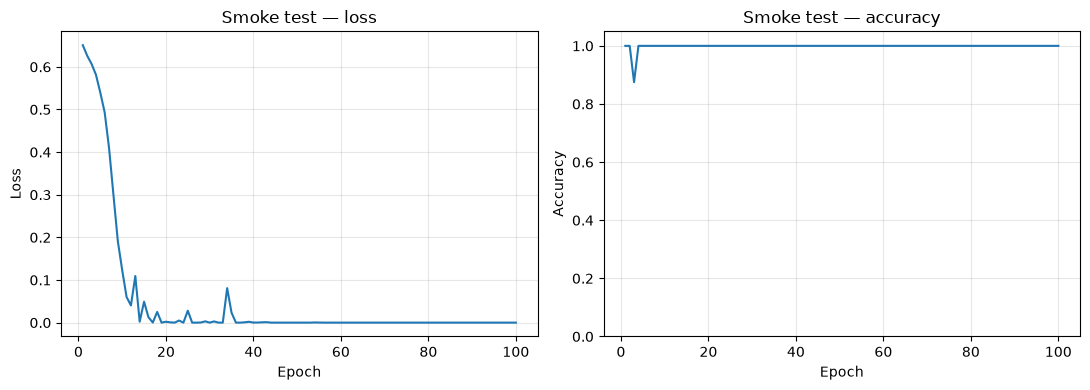

In [7]:
import matplotlib.pyplot as plt

history = smoke_result["history"]

epochs = [h["epoch"] for h in history]
losses = [h["val/loss"] for h in history]
accuracies = [h["val/accuracy"] for h in history]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(epochs, losses)
axes[0].set_title("Smoke test — loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].grid(alpha=0.3)

axes[1].plot(epochs, accuracies)
axes[1].set_title("Smoke test — accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].set_ylim(0, 1.05)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [8]:
# Verify the updated training metrics.
history = smoke_result["history"]
last = history[-1]

required_metrics = [
    "train/loss",
    "train/accuracy",
    "train/eval_loss",
    "train/eval_accuracy",
    "val/loss",
    "val/accuracy",
    "val/macro_f1",
    "val/recall_h1",
    "val/recall_h2",
    "val/pred_h1_rate",
    "val/mean_confidence",
    "diagnostics/accuracy_gap",
    "system/epoch_seconds",
]

missing = [key for key in required_metrics if key not in last]
assert not missing, f"Missing metrics: {missing}"

for key in required_metrics:
    print(f"{key}: {last[key]:.4f}")

print("Optimizer steps:", smoke_result["optimizer_steps"])

# Both loaders contain exactly the same 8 examples.
# Therefore their evaluation accuracies should match.
assert abs(last["diagnostics/accuracy_gap"]) < 1e-8

for key in ("val/recall_h1", "val/recall_h2"):
    assert 0.0 <= last[key] <= 1.0

print("\nAll updated metric checks passed!")


train/loss: 0.0000
train/accuracy: 1.0000
train/eval_loss: 0.0000
train/eval_accuracy: 1.0000
val/loss: 0.0000
val/accuracy: 1.0000
val/macro_f1: 1.0000
val/recall_h1: 1.0000
val/recall_h2: 1.0000
val/pred_h1_rate: 0.2500
val/mean_confidence: 1.0000
diagnostics/accuracy_gap: 0.0000
system/epoch_seconds: 0.1950
Optimizer steps: 100

All updated metric checks passed!


In [9]:
import wandb

with wandb.init(
    project="nlp-art-hs26-project2",
    name="setup-wandb-verification",
    job_type="setup",
    config={
        "model": "BERT-Base",
        "checkpoint": CHECKPOINT,
        "task": "ART",
        "max_length": 128,
        "status": "smoke_test_passed",
    },
) as run:

    run.log({
        "setup/model_smoke_test_passed": 1,
        "setup/metric_checks_passed": 1,
    })

    print("W&B run URL:", run.url)
    print("W&B connection: PASS")


wandb: [wandb.login()] Loaded credentials for https://api.forge.coreweave.com from C:\Users\kimbo\_netrc.
wandb: Currently logged in as: kimbortis (kimbortis-hochschule-luzern) to https://api.forge.coreweave.com. Use `wandb login --relogin` to force relogin


W&B run URL: https://forge.coreweave.com/wandb/kimbortis-hochschule-luzern/nlp-art-hs26-project2/runs/joaa2uk2
W&B connection: PASS


setup/metric_checks_passed,▁
setup/model_smoke_test_passed,▁
setup/metric_checks_passed,1
setup/model_smoke_test_passed,1


## Experiment R1 — Random BERT-Base: Full Training

**Research question:** Can a randomly initialized BERT-Base learn useful patterns from the ART training dataset?

**Hypothesis:** Training accuracy will increase, but generalization may be limited because the model starts without pretrained language representations.

**Model selection:** Lowest validation loss.
**Test data:** Not used.

In [ ]:
from pathlib import Path
import sys
import math
import subprocess

import torch
import numpy as np
import matplotlib.pyplot as plt
import wandb

from torch.utils.data import DataLoader
from transformers import AutoTokenizer

# Find repository root
root = next(
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "project2" / "src" / "training.py").exists()
)

sys.path.insert(0, str(root / "project2" / "src"))

from models import ARTPairwiseBERT, CHECKPOINT
from data_loader import ARTDataset, ARTCollator
from training import set_seed, fit, evaluate

# Experiment configuration
CONFIG = {
    "experiment": "R1",
    "model_type": "random",
    "checkpoint": CHECKPOINT,
    "dataset": "amarfurt/art-nlp-hs26",
    "seed": 42,
    "max_length": 128,
    "batch_size": 4,
    "gradient_accumulation_steps": 4,
    "effective_batch_size": 16,
    "learning_rate": 1e-4,
    "weight_decay": 0.01,
    "optimizer": "AdamW",
    "scheduler": "linear_warmup_decay",
    "warmup_ratio": 0.05,
    "max_epochs": 10,
    "early_stopping_patience": 3,
    "max_grad_norm": 1.0,
    "precision": "bf16",
    "checkpoint_metric": "val/loss",
}

set_seed(CONFIG["seed"])

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

assert device.type == "cuda"
assert torch.cuda.is_bf16_supported()

# Record source revision for reproducibility
def git_output(*args):
    result = subprocess.run(
        ["git", *args],
        cwd=root,
        capture_output=True,
        text=True,
        check=True,
    )
    return result.stdout.strip()

CONFIG["git_commit"] = git_output("rev-parse", "HEAD")
CONFIG["git_dirty"] = bool(git_output("status", "--porcelain"))

print("Experiment:", CONFIG["experiment"])
print("Device:", device)
print("Model:", CHECKPOINT)
print("Learning rate:", CONFIG["learning_rate"])
print("Effective batch size:", CONFIG["effective_batch_size"])
print("Git commit:", CONFIG["git_commit"][:12])
print("Uncommitted changes:", CONFIG["git_dirty"])


In [ ]:

tokenizer = AutoTokenizer.from_pretrained(CHECKPOINT)

train_dataset = ARTDataset(
    split="train",
    tokenizer=tokenizer,
    max_length=CONFIG["max_length"],
)

val_dataset = ARTDataset(
    split="validation",
    tokenizer=tokenizer,
    max_length=CONFIG["max_length"],
)

assert len(train_dataset) == 16801
assert len(val_dataset) == 1000

collator = ARTCollator(tokenizer.pad_token_id)

# Shuffled training batches
train_loader = DataLoader(
    train_dataset,
    batch_size=CONFIG["batch_size"],
    shuffle=True,
    collate_fn=collator,
    num_workers=0,
    pin_memory=True,
)

# Fixed-order training evaluation
train_eval_loader = DataLoader(
    train_dataset,
    batch_size=CONFIG["batch_size"],
    shuffle=False,
    collate_fn=collator,
    num_workers=0,
    pin_memory=True,
)

# Official validation split
val_loader = DataLoader(
    val_dataset,
    batch_size=CONFIG["batch_size"],
    shuffle=False,
    collate_fn=collator,
    num_workers=0,
    pin_memory=True,
)

print("Training examples:", len(train_dataset))
print("Validation examples:", len(val_dataset))
print("Training label counts:", train_dataset.label_counts)
print("Validation label counts:", val_dataset.label_counts)

batch = next(iter(train_loader))

assert batch["input_ids"].shape[1] == 2
assert batch["input_ids"].shape[-1] <= 128
assert batch["attention_mask"].shape == batch["input_ids"].shape
assert set(batch["labels"].tolist()).issubset({0, 1})

print("Batch input:", tuple(batch["input_ids"].shape))
print("Batch labels:", tuple(batch["labels"].shape))
print("DataLoader verification: PASS")


In [ ]:

set_seed(CONFIG["seed"])

model = ARTPairwiseBERT(
    initialization="random"
).to(device)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=CONFIG["learning_rate"],
    weight_decay=CONFIG["weight_decay"],
)

# Calculate optimizer updates, accounting for accumulation
updates_per_epoch = math.ceil(
    len(train_loader)
    / CONFIG["gradient_accumulation_steps"]
)

total_updates = (
    updates_per_epoch * CONFIG["max_epochs"]
)

warmup_steps = max(
    1,
    int(total_updates * CONFIG["warmup_ratio"])
)

# Linear warmup followed by linear decay
def lr_factor(step):
    if step < warmup_steps:
        return float(step + 1) / warmup_steps

    return max(
        0.0,
        (total_updates - step)
        / max(1, total_updates - warmup_steps),
    )

scheduler = torch.optim.lr_scheduler.LambdaLR(
    optimizer,
    lr_lambda=lr_factor,
)

CONFIG["updates_per_epoch"] = updates_per_epoch
CONFIG["total_planned_updates"] = total_updates
CONFIG["warmup_steps"] = warmup_steps

checkpoint_path = (
    root / "project2" / "artifacts" / "checkpoints"
    / "r1_random_bertbase_lr1e-4_s42.pt"
)

parameter_count = sum(
    p.numel() for p in model.parameters()
)

print("Parameters:", f"{parameter_count:,}")
print("Optimizer updates per epoch:", updates_per_epoch)
print("Maximum optimizer updates:", total_updates)
print("Warmup steps:", warmup_steps)
print("Initial scheduled LR:", optimizer.param_groups[0]["lr"])
print("Checkpoint:", checkpoint_path)


In [ ]:

run_name = "r1-random-bertbase-lr1e-4-b16-s42"

with wandb.init(
    project="nlp-art-hs26-project2",
    name=run_name,
    group="random-bertbase",
    job_type="train",
    tags=["project2", "random", "bert-base", "R1"],
    config=CONFIG,
) as run:

    print("W&B:", run.url)

    result = fit(
        model=model,
        train_loader=train_loader,
        train_eval_loader=train_eval_loader,
        val_loader=val_loader,
        optimizer=optimizer,
        scheduler=scheduler,
        device=device,
        epochs=CONFIG["max_epochs"],
        checkpoint_path=checkpoint_path,
        patience=CONFIG["early_stopping_patience"],
        min_delta=0.0,
        accumulation_steps=CONFIG["gradient_accumulation_steps"],
        max_grad_norm=CONFIG["max_grad_norm"],
        run=run,
        print_every=1,
    )

    # fit() restores the lowest-val-loss checkpoint.
    selected_val = evaluate(
        model,
        val_loader,
        device,
    )

    run.summary["selected/val_macro_f1"] = (
        selected_val["macro_f1"]
    )
    run.summary["selected/val_recall_h1"] = (
        selected_val["recall_h1"]
    )
    run.summary["selected/val_recall_h2"] = (
        selected_val["recall_h2"]
    )

    print("\n=== R1 RESULTS ===")
    print("Best epoch:", result["best_epoch"])
    print("Best val loss:", result["best_val_loss"])
    print("Val accuracy at best checkpoint:",
          result["best_val_accuracy"])
    print("Optimizer updates:", result["optimizer_steps"])
    print("Checkpoint:", result["checkpoint"])

print("\nW&B run completed.")


In [ ]:

history = result["history"]

epochs = [row["epoch"] for row in history]

# Loss curves
plt.figure(figsize=(9, 4.5))
plt.plot(
    epochs,
    [row["train/eval_loss"] for row in history],
    marker="o",
    label="Training loss (eval mode)",
)
plt.plot(
    epochs,
    [row["val/loss"] for row in history],
    marker="o",
    label="Validation loss",
)
plt.axvline(
    result["best_epoch"],
    linestyle="--",
    label="Best checkpoint",
)

plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title("R1 — Random BERT-Base: Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Accuracy curves
plt.figure(figsize=(9, 4.5))
plt.plot(
    epochs,
    [row["train/eval_accuracy"] for row in history],
    marker="o",
    label="Training accuracy (eval mode)",
)
plt.plot(
    epochs,
    [row["val/accuracy"] for row in history],
    marker="o",
    label="Validation accuracy",
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("R1 — Random BERT-Base: Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [ ]:
required_epoch_metrics = [
    "train/loss",
    "train/accuracy",
    "train/eval_loss",
    "train/eval_accuracy",
    "val/loss",
    "val/accuracy",
    "val/macro_f1",
    "val/recall_h1",
    "val/recall_h2",
    "val/pred_h1_rate",
    "val/mean_confidence",
    "diagnostics/accuracy_gap",
    "system/epoch_seconds",
]

for row in history:
    missing = [
        key for key in required_epoch_metrics
        if key not in row
    ]
    assert not missing, f"Missing metrics: {missing}"

assert result["best_epoch"] is not None
assert result["optimizer_steps"] > 0
assert Path(result["checkpoint"]).exists()

print("Epoch metrics: PASS")
print("Checkpoint exists: PASS")
print("Optimizer updates: PASS")

print("\n=== SELECTED CHECKPOINT ===")
print("Best epoch:", result["best_epoch"])
print("Validation loss:", round(selected_val["loss"], 4))
print("Validation accuracy:", round(selected_val["accuracy"], 4))
print("Macro-F1:", round(selected_val["macro_f1"], 4))
print("H1 recall:", round(selected_val["recall_h1"], 4))
print("H2 recall:", round(selected_val["recall_h2"], 4))
print("H1 prediction rate:", round(selected_val["pred_h1_rate"], 4))
print("Confusion matrix:")
print(np.array(selected_val["confusion_matrix"]))
